In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully")

Libraries imported successfully


In [10]:
df = pd.read_csv(
    "C:\Pancreas_\clinical_data\pancreatic_clinical_stage_mo.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (40000, 20)


In [11]:
df.head()

,Patient_ID,Country,Age,Gender,Smoking_History,Obesity,Diabetes,Chronic_Pancreatitis,Family_History,Hereditary_Condition,Jaundice,Abdominal_Discomfort,Back_Pain,Weight_Loss,Development_of_Type2_Diabetes,Alcohol_Consumption,Physical_Activity_Level,Diet_Processed_Food,Access_to_Healthcare,Stage_at_Diagnosis
0,P32824,Canada,71,Female,1,1,1,0,0,1,1,1,1,1,1,1,Low,High,Medium,Stage IV
1,P16299,Brazil,59,Male,0,1,0,0,1,0,0,0,1,0,0,1,Medium,Medium,Medium,Stage II
2,P28506,Australia,71,Male,0,0,0,0,1,0,0,1,1,0,0,0,Medium,Medium,Medium,Stage III
3,P06690,Germany,42,Female,0,0,0,0,0,0,0,0,0,0,0,1,High,Medium,High,Stage I
4,P26894,Germany,70,Female,1,0,0,0,0,0,1,1,0,0,0,1,Low,Medium,Medium,Stage III


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Patient_ID                     40000 non-null  str  
 1   Country                        40000 non-null  str  
 2   Age                            40000 non-null  int64
 3   Gender                         40000 non-null  str  
 4   Smoking_History                40000 non-null  int64
 5   Obesity                        40000 non-null  int64
 6   Diabetes                       40000 non-null  int64
 7   Chronic_Pancreatitis           40000 non-null  int64
 8   Family_History                 40000 non-null  int64
 9   Hereditary_Condition           40000 non-null  int64
 10  Jaundice                       40000 non-null  int64
 11  Abdominal_Discomfort           40000 non-null  int64
 12  Back_Pain                      40000 non-null  int64
 13  Weight_Loss                

In [13]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Patient_ID', 'Country', 'Age', 'Gender', 'Smoking_History', 'Obesity', 'Diabetes', 'Chronic_Pancreatitis', 'Family_History', 'Hereditary_Condition', 'Jaundice', 'Abdominal_Discomfort', 'Back_Pain', 'Weight_Loss', 'Development_of_Type2_Diabetes', 'Alcohol_Consumption', 'Physical_Activity_Level', 'Diet_Processed_Food', 'Access_to_Healthcare', 'Stage_at_Diagnosis']


In [14]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Patient_ID                       0
Country                          0
Age                              0
Gender                           0
Smoking_History                  0
Obesity                          0
Diabetes                         0
Chronic_Pancreatitis             0
Family_History                   0
Hereditary_Condition             0
Jaundice                         0
Abdominal_Discomfort             0
Back_Pain                        0
Weight_Loss                      0
Development_of_Type2_Diabetes    0
Alcohol_Consumption              0
Physical_Activity_Level          0
Diet_Processed_Food              0
Access_to_Healthcare             0
Stage_at_Diagnosis               0
dtype: int64


In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [16]:
print("Number of unique Patient IDs:",
      df["Patient_ID"].nunique())

print("\nFirst IDs:")
print(df["Patient_ID"].head())

print("\nLast IDs:")
print(df["Patient_ID"].tail())

Number of unique Patient IDs: 40000

First IDs:
0    P32824
1    P16299
2    P28506
3    P06690
4    P26894
Name: Patient_ID, dtype: str

Last IDs:
39995    P06266
39996    P11285
39997    P38159
39998    P00861
39999    P15796
Name: Patient_ID, dtype: str


In [17]:
stage_counts = df["Stage_at_Diagnosis"].value_counts()

print(stage_counts)

Stage_at_Diagnosis
Stage IV     10000
Stage II     10000
Stage III    10000
Stage I      10000
Name: count, dtype: int64


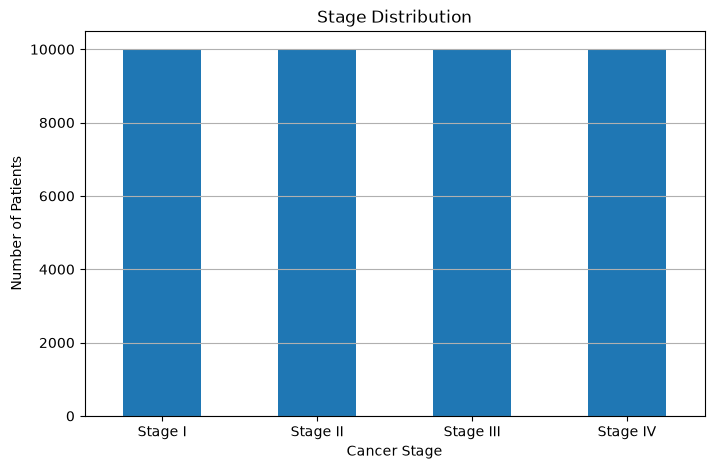

In [18]:
plt.figure(figsize=(8, 5))

stage_counts.reindex(
    ["Stage I", "Stage II", "Stage III", "Stage IV"]
).plot(kind="bar")

plt.title("Stage Distribution")
plt.xlabel("Cancer Stage")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [19]:
X = df.drop(
    columns=[
        "Stage_at_Diagnosis",
        "Patient_ID"
    ]
)

y = df["Stage_at_Diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

X shape: (40000, 18)
y shape: (40000,)

X columns:
['Country', 'Age', 'Gender', 'Smoking_History', 'Obesity', 'Diabetes', 'Chronic_Pancreatitis', 'Family_History', 'Hereditary_Condition', 'Jaundice', 'Abdominal_Discomfort', 'Back_Pain', 'Weight_Loss', 'Development_of_Type2_Diabetes', 'Alcohol_Consumption', 'Physical_Activity_Level', 'Diet_Processed_Food', 'Access_to_Healthcare']

Target:
Stage_at_Diagnosis


In [20]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Country', 'Gender', 'Physical_Activity_Level', 'Diet_Processed_Food', 'Access_to_Healthcare']

Numerical features:
['Age', 'Smoking_History', 'Obesity', 'Diabetes', 'Chronic_Pancreatitis', 'Family_History', 'Hereditary_Condition', 'Jaundice', 'Abdominal_Discomfort', 'Back_Pain', 'Weight_Loss', 'Development_of_Type2_Diabetes', 'Alcohol_Consumption']


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 32000
Testing samples: 8000


In [22]:
print("Training distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test.value_counts().sort_index())

Training distribution:
Stage_at_Diagnosis
Stage I      8000
Stage II     8000
Stage III    8000
Stage IV     8000
Name: count, dtype: int64

Testing distribution:
Stage_at_Diagnosis
Stage I      2000
Stage II     2000
Stage III    2000
Stage IV     2000
Name: count, dtype: int64


In [23]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessor created successfully")

Preprocessor created successfully


In [24]:
rf_model = RandomForestClassifier(
    n_estimators=700,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

print(rf_model)

RandomForestClassifier(n_estimators=700, n_jobs=-1, random_state=42)


In [25]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", rf_model)
    ]
)

print("Random Forest pipeline created")

Random Forest pipeline created


In [26]:
print("Training Random Forest...")

rf_pipeline.fit(
    X_train,
    y_train
)

print("Training completed!")

Training Random Forest...
Training completed!


In [27]:
rf_predictions = rf_pipeline.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(rf_predictions))

Predictions generated successfully!
Number of predictions: 8000


In [28]:
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

print(
    "Random Forest Accuracy:",
    round(rf_accuracy * 100, 2),
    "%"
)

Random Forest Accuracy: 90.74 %


In [29]:
rf_balanced_accuracy = balanced_accuracy_score(
    y_test,
    rf_predictions
)

rf_macro_f1 = f1_score(
    y_test,
    rf_predictions,
    average="macro"
)

rf_weighted_f1 = f1_score(
    y_test,
    rf_predictions,
    average="weighted"
)

print("Random Forest Results")
print("=" * 40)

print(
    "Accuracy:",
    round(rf_accuracy * 100, 2),
    "%"
)

print(
    "Balanced Accuracy:",
    round(rf_balanced_accuracy * 100, 2),
    "%"
)

print(
    "Macro F1:",
    round(rf_macro_f1 * 100, 2),
    "%"
)

print(
    "Weighted F1:",
    round(rf_weighted_f1 * 100, 2),
    "%"
)

Random Forest Results
Accuracy: 90.74 %
Balanced Accuracy: 90.74 %
Macro F1: 90.75 %
Weighted F1: 90.75 %


In [30]:
print(
    classification_report(
        y_test,
        rf_predictions,
        labels=[
            "Stage I",
            "Stage II",
            "Stage III",
            "Stage IV"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Stage I       0.91      0.91      0.91      2000
    Stage II       0.88      0.88      0.88      2000
   Stage III       0.90      0.91      0.90      2000
    Stage IV       0.94      0.93      0.93      2000

    accuracy                           0.91      8000
   macro avg       0.91      0.91      0.91      8000
weighted avg       0.91      0.91      0.91      8000



In [31]:
cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=[
        "Stage I",
        "Stage II",
        "Stage III",
        "Stage IV"
    ]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1816  184    0    0]
 [ 175 1768   57    0]
 [   0   65 1818  117]
 [   0    0  143 1857]]


<Figure size 800x600 with 0 Axes>

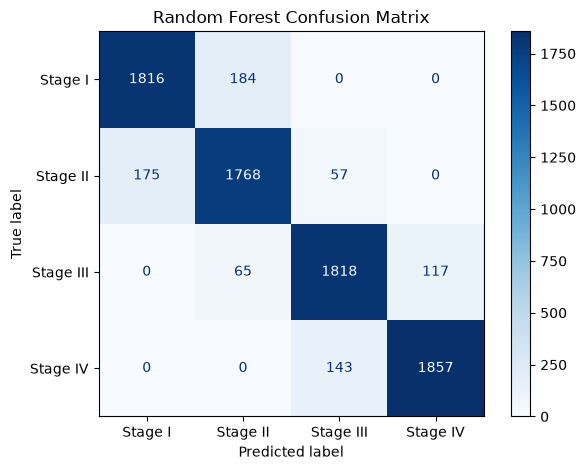

In [32]:
plt.figure(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Stage I",
        "Stage II",
        "Stage III",
        "Stage IV"
    ]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [33]:
feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
20,numerical__Age,0.449675
30,numerical__Weight_Loss,0.079837
27,numerical__Jaundice,0.066926
28,numerical__Abdominal_Discomfort,0.057770
29,numerical__Back_Pain,0.052059
31,numerical__Development_of_Type2_Diabetes,0.022707
23,numerical__Diabetes,0.020245
11,categorical__Physical_Activity_Level_High,0.019721
12,categorical__Physical_Activity_Level_Low,0.018808
21,numerical__Smoking_History,0.015705


In [34]:
rf_probabilities = rf_pipeline.predict_proba(
    X_test
)

print("Probability shape:")
print(rf_probabilities.shape)

Probability shape:
(8000, 4)


In [35]:
sample_probabilities = rf_probabilities[0]

for stage_name, probability in zip(
    rf_pipeline.classes_,
    sample_probabilities
):
    print(
        stage_name,
        ":",
        round(probability * 100, 2),
        "%"
    )

Stage I : 0.0 %
Stage II : 0.0 %
Stage III : 15.57 %
Stage IV : 84.43 %


In [36]:
sample_patient = X_test.iloc[[0]]

predicted_stage = rf_pipeline.predict(
    sample_patient
)[0]

probabilities = rf_pipeline.predict_proba(
    sample_patient
)[0]

confidence = probabilities.max()

print("Predicted Stage:", predicted_stage)
print("Confidence:", round(confidence * 100, 2), "%")

Predicted Stage: Stage IV
Confidence: 84.43 %


In [37]:
import joblib

joblib.dump(
    rf_pipeline,
    "clinical_stage_random_forest.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [38]:
!pip install xgboost


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [40]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Classes:")
print(label_encoder.classes_)

print("\nEncoded classes:")
print(np.unique(y_train_encoded))

Classes:
['Stage I' 'Stage II' 'Stage III' 'Stage IV']

Encoded classes:
[0 1 2 3]


In [41]:
xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("XGBoost preprocessor created!")

XGBoost preprocessor created!


In [42]:
X_train_xgb = xgb_preprocessor.fit_transform(X_train)

X_test_xgb = xgb_preprocessor.transform(X_test)

print("Training shape:", X_train_xgb.shape)
print("Testing shape:", X_test_xgb.shape)

Training shape: (32000, 33)
Testing shape: (8000, 33)


In [44]:
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)


In [45]:
print("Training XGBoost...")

xgb_model.fit(
    X_train_xgb,
    y_train_encoded
)

print("XGBoost training completed!")

Training XGBoost...
XGBoost training completed!


In [46]:
xgb_predictions = xgb_model.predict(
    X_test_xgb
)

print("Predictions generated!")
print("Number of predictions:", len(xgb_predictions))

Predictions generated!
Number of predictions: 8000


In [47]:
xgb_accuracy = accuracy_score(
    y_test_encoded,
    xgb_predictions
)

print(
    "XGBoost Accuracy:",
    round(xgb_accuracy * 100, 2),
    "%"
)

XGBoost Accuracy: 91.31 %


In [48]:
xgb_balanced_accuracy = balanced_accuracy_score(
    y_test_encoded,
    xgb_predictions
)

xgb_macro_f1 = f1_score(
    y_test_encoded,
    xgb_predictions,
    average="macro"
)

xgb_weighted_f1 = f1_score(
    y_test_encoded,
    xgb_predictions,
    average="weighted"
)

print("XGBoost Results")
print("=" * 40)

print(
    "Accuracy:",
    round(xgb_accuracy * 100, 2),
    "%"
)

print(
    "Balanced Accuracy:",
    round(xgb_balanced_accuracy * 100, 2),
    "%"
)

print(
    "Macro F1:",
    round(xgb_macro_f1 * 100, 2),
    "%"
)

print(
    "Weighted F1:",
    round(xgb_weighted_f1 * 100, 2),
    "%"
)

XGBoost Results
Accuracy: 91.31 %
Balanced Accuracy: 91.31 %
Macro F1: 91.32 %
Weighted F1: 91.32 %


In [49]:
print(
    classification_report(
        y_test_encoded,
        xgb_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Stage I       0.92      0.92      0.92      2000
    Stage II       0.89      0.90      0.89      2000
   Stage III       0.91      0.91      0.91      2000
    Stage IV       0.94      0.93      0.94      2000

    accuracy                           0.91      8000
   macro avg       0.91      0.91      0.91      8000
weighted avg       0.91      0.91      0.91      8000



In [50]:
xgb_cm = confusion_matrix(
    y_test_encoded,
    xgb_predictions
)

print(xgb_cm)

[[1830  170    0    0]
 [ 155 1792   53    0]
 [   0   58 1815  127]
 [   0    0  132 1868]]


In [51]:
#xgboost feature importance
xgb_feature_names = (
    xgb_preprocessor
    .get_feature_names_out()
)

xgb_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

xgb_importance.head(20)

,Feature,Importance
20,numerical__Age,0.282910
30,numerical__Weight_Loss,0.149273
27,numerical__Jaundice,0.116460
28,numerical__Abdominal_Discomfort,0.064951
29,numerical__Back_Pain,0.058849
11,categorical__Physical_Activity_Level_High,0.024752
31,numerical__Development_of_Type2_Diabetes,0.021968
12,categorical__Physical_Activity_Level_Low,0.020982
23,numerical__Diabetes,0.020825
14,categorical__Diet_Processed_Food_High,0.020804


In [52]:
xgb_probabilities = xgb_model.predict_proba(
    X_test_xgb
)

print("Probability shape:")
print(xgb_probabilities.shape)

Probability shape:
(8000, 4)


In [53]:
sample_index = 0

predicted_class = np.argmax(
    xgb_probabilities[sample_index]
)

predicted_stage = label_encoder.inverse_transform(
    [predicted_class]
)[0]

confidence = np.max(
    xgb_probabilities[sample_index]
)

print("Predicted Stage:", predicted_stage)
print("Confidence:", round(confidence * 100, 2), "%")

Predicted Stage: Stage IV
Confidence: 99.95 %


In [54]:
import joblib

joblib.dump(
    xgb_model,
    "clinical_stage_xgboost.pkl"
)

joblib.dump(
    xgb_preprocessor,
    "clinical_stage_xgb_preprocessor.pkl"
)

joblib.dump(
    label_encoder,
    "clinical_stage_label_encoder.pkl"
)

print("XGBoost model and preprocessing files saved!")

XGBoost model and preprocessing files saved!


In [56]:
from sklearn.ensemble import ExtraTreesClassifier

print("Extra Trees imported successfully!")
#preprocessing
extra_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Extra Trees preprocessor created!")

Extra Trees imported successfully!
Extra Trees preprocessor created!


In [57]:
X_train_extra = extra_preprocessor.fit_transform(X_train)
X_test_extra = extra_preprocessor.transform(X_test)

print("Training shape:", X_train_extra.shape)
print("Testing shape:", X_test_extra.shape)

Training shape: (32000, 33)
Testing shape: (8000, 33)


In [58]:
extra_model = ExtraTreesClassifier(
    n_estimators=700,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

print(extra_model)

ExtraTreesClassifier(n_estimators=700, n_jobs=-1, random_state=42)


In [59]:
print("Training Extra Trees...")

extra_model.fit(
    X_train_extra,
    y_train
)

print("Extra Trees training completed!")

Training Extra Trees...
Extra Trees training completed!


In [60]:
extra_predictions = extra_model.predict(
    X_test_extra
)

print("Predictions generated!")

Predictions generated!


In [61]:
extra_accuracy = accuracy_score(
    y_test,
    extra_predictions
)

extra_balanced_accuracy = balanced_accuracy_score(
    y_test,
    extra_predictions
)

extra_macro_f1 = f1_score(
    y_test,
    extra_predictions,
    average="macro"
)

extra_weighted_f1 = f1_score(
    y_test,
    extra_predictions,
    average="weighted"
)

print("Extra Trees Results")
print("=" * 40)

print("Accuracy:",
      round(extra_accuracy * 100, 2), "%")

print("Balanced Accuracy:",
      round(extra_balanced_accuracy * 100, 2), "%")

print("Macro F1:",
      round(extra_macro_f1 * 100, 2), "%")

print("Weighted F1:",
      round(extra_weighted_f1 * 100, 2), "%")

Extra Trees Results
Accuracy: 87.92 %
Balanced Accuracy: 87.92 %
Macro F1: 87.93 %
Weighted F1: 87.93 %


In [62]:
print(
    classification_report(
        y_test,
        extra_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Stage I       0.90      0.88      0.89      2000
    Stage II       0.84      0.86      0.85      2000
   Stage III       0.87      0.87      0.87      2000
    Stage IV       0.91      0.91      0.91      2000

    accuracy                           0.88      8000
   macro avg       0.88      0.88      0.88      8000
weighted avg       0.88      0.88      0.88      8000



In [63]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "Extra Trees"
    ],

    "Accuracy": [
        rf_accuracy * 100,
        xgb_accuracy * 100,
        extra_accuracy * 100
    ],

    "Balanced Accuracy": [
        rf_balanced_accuracy * 100,
        xgb_balanced_accuracy * 100,
        extra_balanced_accuracy * 100
    ],

    "Macro F1": [
        rf_macro_f1 * 100,
        xgb_macro_f1 * 100,
        extra_macro_f1 * 100
    ],

    "Weighted F1": [
        rf_weighted_f1 * 100,
        xgb_weighted_f1 * 100,
        extra_weighted_f1 * 100
    ]
})

comparison.round(2)

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Random Forest,90.74,90.74,90.75,90.75
1,XGBoost,91.31,91.31,91.32,91.32
2,Extra Trees,87.92,87.92,87.93,87.93


In [64]:
best_model = comparison.loc[
    comparison["Accuracy"].idxmax()
]

print("🏆 BEST MODEL")
print("=" * 40)

print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 2), "%")
print("Balanced Accuracy:",
      round(best_model["Balanced Accuracy"], 2), "%")
print("Macro F1:",
      round(best_model["Macro F1"], 2), "%")

🏆 BEST MODEL
Model: XGBoost
Accuracy: 91.31 %
Balanced Accuracy: 91.31 %
Macro F1: 91.32 %


In [65]:
import joblib
import os

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save Extra Trees model
joblib.dump(
    extra_model,
    "../models/extra_trees_model.pkl"
)

# Save Extra Trees preprocessor
joblib.dump(
    extra_preprocessor,
    "../models/extra_trees_preprocessor.pkl"
)

print("Extra Trees model saved successfully!")
print("Extra Trees preprocessor saved successfully!")

Extra Trees model saved successfully!
Extra Trees preprocessor saved successfully!


In [66]:
import joblib
import os

MODEL_DIR = r"C:\Pancreas_\models"

models = {
    "Random Forest": "random_forest_model.pkl",
    "XGBoost": "xgboost_model.pkl",
    "Extra Trees": "extra_trees_model.pkl"
}

preprocessors = {
    "Random Forest": "random_forest_preprocessor.pkl",
    "XGBoost": "xgboost_preprocessor.pkl",
    "Extra Trees": "extra_trees_preprocessor.pkl"
}

for name, filename in models.items():

    path = os.path.join(MODEL_DIR, filename)

    model = joblib.load(path)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Model type:")
    print(type(model))

    print("\nIs Pipeline?")
    print(hasattr(model, "steps"))

    if hasattr(model, "steps"):
        print("\nPipeline steps:")
        print(model.steps)


print("\n\n" + "#" * 70)
print("PREPROCESSORS")
print("#" * 70)

for name, filename in preprocessors.items():

    path = os.path.join(MODEL_DIR, filename)

    preprocessor = joblib.load(path)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Preprocessor type:")
    print(type(preprocessor))

    if hasattr(preprocessor, "feature_names_in_"):
        print(
            "Expected input features:",
            len(preprocessor.feature_names_in_)
        )

        print(
            list(preprocessor.feature_names_in_)
        )


Random Forest
Model type:
<class 'sklearn.pipeline.Pipeline'>

Is Pipeline?
True

Pipeline steps:
[('preprocessor', ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Country', 'Gender',
                                  'Physical_Activity_Level',
                                  'Diet_Processed_Food',
                                  'Access_to_Healthcare']),
                                ('numerical', 'passthrough',
                                 ['Age', 'Smoking_History', 'Obesity',
                                  'Diabetes', 'Chronic_Pancreatitis',
                                  'Family_History', 'Hereditary_Condition',
                                  'Jaundice', 'Abdominal_Discomfort',
                                  'Back_Pain', 'Weight_Loss',
                                  'Development_of_T

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Pancreas_\\models\\random_forest_preprocessor.pkl'